第 8 章：MLP 多层感知机

学习前向传播、反向传播、激活函数、梯度消失与梯度爆炸、初始化、正则化。

项目：房价预测、分类任务、训练曲线分析。


一、使用 MLP 实现 heart-disease.csv 分类

In [9]:
import copy
import warnings

import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split

# 去除警告
warnings.filterwarnings("ignore")

# 设置全局随机值
torch.manual_seed(23)

In [6]:
# 0、确定设备
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"当前设备：{device}")

当前设备：mps


In [33]:
# 1、定义 HeartDisease dataset
class HeartDiseaseDataset(Dataset):
    def __init__(self, features: pd.DataFrame, targets: pd.Series):
        features = features.reset_index(drop=True)
        targets = targets.reset_index(drop=True)
        self.features = torch.tensor(features.to_numpy(),dtype=torch.float32)
        self.targets = torch.tensor(targets.to_numpy(),dtype=torch.float32)

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):
        return self.features[index], self.targets[index]


In [34]:
# 2、定义 HeartDisease MLP 模型 （分类任务）
class HeartDiseaseMLP(nn.Module):
    def __init__(self):
        super().__init__()
        # heart-disease.csv 有13个特征数据
        self.network = nn.Sequential(
            nn.Linear(in_features=13, out_features=8),
            nn.ReLU(),
            nn.Linear(in_features=8, out_features=4),
            nn.ReLU(),
            nn.Linear(in_features=4, out_features=1),
        )
    def forward(self, x):
        return self.network(x)

In [35]:
# 3、加载数据
df = pd.read_csv("../data/ml/heart-disease.csv")
print(len(df))
df.head()

1025


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [36]:
# 5、分割数据
# train:valid:test = 8:1:1
train_indices, valid_indices, test_indices = random_split(
    range(len(df)),
    [809, 108, 108],
    generator=torch.Generator().manual_seed(23)
)
print(len(train_indices), len(valid_indices), len(test_indices))

809 108 108


In [37]:
# 6、数据预处理
# 获取所有特征列tag
feature_columns = df.columns[:-1]
print(f"feature_columns: {feature_columns}")
# 获取train，valid，test数据df
train_df = df.iloc[train_indices.indices]
valid_df = df.iloc[valid_indices.indices]
test_df = df.iloc[test_indices.indices]

# 将所有特征列统一转换为 float64， 直接重新构造 DataFrame，确保特征列全部是 float64
train_df = train_df.astype({col: "float64" for col in feature_columns})
valid_df = valid_df.astype({col: "float64" for col in feature_columns})
test_df = test_df.astype({col: "float64" for col in feature_columns})
print("train_df len:", len(train_df), len(valid_df), len(test_df))

# 计算训练集每一列的 mean，std
train_feature_mean = train_df.loc[:, feature_columns].mean()
train_feature_std = train_df.loc[:, feature_columns].std()

# 处理 train，valid，test 数据中的所有缺失值
for each_df in (train_df, valid_df, test_df):
    each_df.loc[:, feature_columns] = each_df.loc[:, feature_columns].fillna(train_feature_mean) # 填充缺失值
    each_df.loc[:, feature_columns] = (each_df.loc[:, feature_columns] - train_feature_mean) / train_feature_std

# 构造数据
train_dataset = HeartDiseaseDataset(train_df.iloc[:, :-1], train_df.iloc[:, -1])
valid_dataset = HeartDiseaseDataset(valid_df.iloc[:, :-1], valid_df.iloc[:, -1])
test_dataset = HeartDiseaseDataset(test_df.iloc[:, :-1], test_df.iloc[:, -1])

# 构造数据加载器
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=16, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print(train_df.index)
print(train_df.shape)

print(type(train_dataset.features))
print(type(train_dataset.targets))

print(train_dataset.features.shape)
print(train_dataset.targets.shape)
x, y = next(iter(train_dataloader))
print(x.shape, y.shape)


feature_columns: Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='str')
train_df len: 809 108 108
Index([ 816,  743,  605,  348,  550,  757,  898,  754,  908, 1012,
       ...
        680,  755,  143,  970,  860,  129,  529,  340,  416,  651],
      dtype='int64', length=809)
(809, 14)
<class 'torch.Tensor'>
<class 'torch.Tensor'>
torch.Size([809, 13])
torch.Size([809])
torch.Size([64, 13]) torch.Size([64])


In [71]:
# 7、训练

model = HeartDiseaseMLP().to(device)

#
# 分类任务选用 二分类损失函数选用 BCEWithLogitsLoss 和 Adam
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

best_model_state_dict = model.state_dict()
best_loss = float("inf")

train_losses = []
train_accuracies = []
valid_losses = []
valid_accuracies = []

epochs = 300
for epoch in range(epochs):

    model.train()
    train_sample = 0
    train_loss_sum = 0
    train_correct = 0
    for x, target in train_dataloader:
        x, target = x.to(device), target.to(device).reshape(-1, 1)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()
        size = float(x.shape[0])
        train_sample += size
        train_loss_sum += loss.item() * size

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).long()
        train_correct += (predictions == target.long()).sum().item()


    train_loss = train_loss_sum / train_sample
    train_losses.append(train_loss)
    train_accuracy = train_correct / train_sample
    train_accuracies.append(train_accuracy)

    model.eval()
    valid_sample = 0
    valid_loss_sum = 0
    valid_correct = 0
    with torch.no_grad():
        for x, target in valid_dataloader:
            x, target = x.to(device), target.to(device).reshape(-1, 1)
            logits = model(x)
            loss = criterion(logits, target)
            size = float(x.shape[0])
            valid_sample += size
            valid_loss_sum += loss.item() * size

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).long()
            valid_correct += (predictions == target.long()).sum().item()

    valid_loss = valid_loss_sum / valid_sample
    valid_losses.append(valid_loss)
    valid_accuracy = valid_correct / valid_sample
    valid_accuracies.append(valid_accuracy)

    if valid_loss < best_loss:
        best_loss = valid_loss
        # 必须复制参数，不能直接保存 state_dict() 的引用
        best_model_state_dict = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

    if (epoch + 1) % 10 == 0:
        print(f"epoch: {epoch}, train_loss: {train_loss:.4f}, valid_loss: {valid_loss:.4f}, train_accuracy: {train_accuracy:.4f}, valid_accuracy: {valid_accuracy:.4f}")

torch.save(best_model_state_dict, "HeartDiseaseMLP_best_model_state_dict.pth")
print(f"best_model_state_dict: {best_model_state_dict}")
print(f"best_loss: {best_loss}")

epoch: 9, train_loss: 0.6236, valid_loss: 0.6107, train_accuracy: 0.4784, valid_accuracy: 0.5000
epoch: 19, train_loss: 0.5118, valid_loss: 0.4958, train_accuracy: 0.8269, valid_accuracy: 0.8333
epoch: 29, train_loss: 0.4655, valid_loss: 0.4526, train_accuracy: 0.8690, valid_accuracy: 0.8611
epoch: 39, train_loss: 0.3657, valid_loss: 0.3686, train_accuracy: 0.8591, valid_accuracy: 0.8241
epoch: 49, train_loss: 0.3218, valid_loss: 0.3461, train_accuracy: 0.8714, valid_accuracy: 0.8426
epoch: 59, train_loss: 0.3029, valid_loss: 0.3417, train_accuracy: 0.8838, valid_accuracy: 0.8611
epoch: 69, train_loss: 0.2892, valid_loss: 0.3383, train_accuracy: 0.8826, valid_accuracy: 0.8704
epoch: 79, train_loss: 0.2782, valid_loss: 0.3376, train_accuracy: 0.8863, valid_accuracy: 0.8704
epoch: 89, train_loss: 0.2679, valid_loss: 0.3358, train_accuracy: 0.8888, valid_accuracy: 0.8796
epoch: 99, train_loss: 0.2577, valid_loss: 0.3330, train_accuracy: 0.8986, valid_accuracy: 0.8889
epoch: 109, train_los

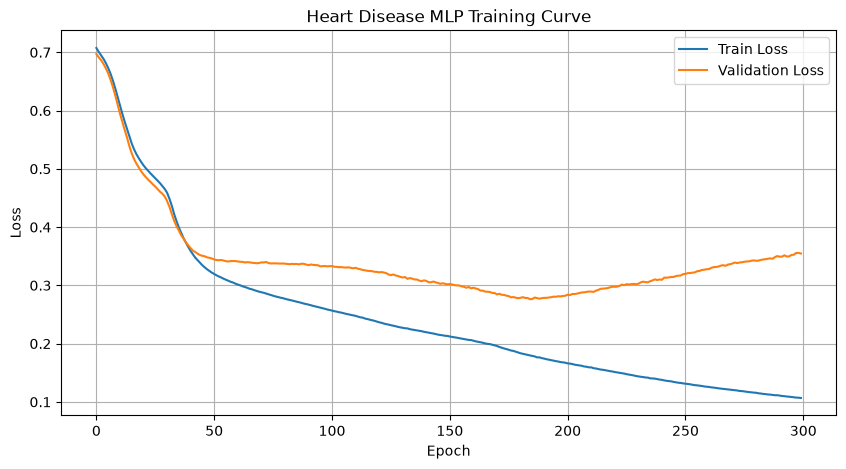

In [72]:

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(valid_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Heart Disease MLP Training Curve")

plt.legend()
plt.grid(True)

plt.show()
# 曲线表现	可能的问题	改进方向
# Train Loss ↓，Valid Loss ↓	正常收敛	继续训练观察
# Train Loss ↓，Valid Loss ↑	过拟合	Early Stopping、Dropout、正则化
# Train Loss 高，Valid Loss 高	欠拟合	增加模型容量、调整学习率
# Train Loss、Valid Loss 都不下降	模型没有有效学习	检查数据、标签、损失函数和学习率

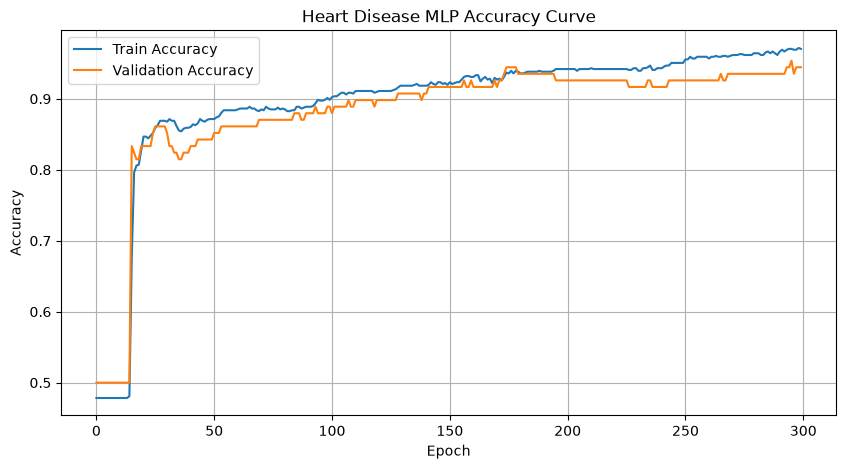

In [73]:
plt.figure(figsize=(10, 5))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(valid_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Heart Disease MLP Accuracy Curve")

plt.legend()
plt.grid(True)

plt.show()

In [62]:
# 8、测试
test_model = HeartDiseaseMLP().to(device)

load_best_model_state_dict = torch.load(
    "HeartDiseaseMLP_best_model_state_dict.pth",
    map_location=device
)

test_model.load_state_dict(load_best_model_state_dict)

criterion = nn.BCEWithLogitsLoss()

# 推理
test_model.eval()

test_sample = 0
test_loss_sum = 0

all_predictions = []
all_targets = []
all_probabilities = []

with torch.inference_mode():

    for x, target in test_dataloader:

        x = x.to(device)
        target = target.to(device).reshape(-1, 1)

        # 1. 模型输出 Logits
        logits = test_model(x)

        # 2. 计算损失
        loss = criterion(logits, target)

        # 3. Sigmoid 转换为概率
        probabilities = torch.sigmoid(logits)

        # 4. 根据 0.5 阈值转换为类别
        predictions = (probabilities >= 0.5).long()

        # 5. 保存预测结果
        all_predictions.extend(predictions.cpu().numpy().flatten())
        all_targets.extend(target.cpu().numpy().flatten())
        all_probabilities.extend(probabilities.cpu().numpy().flatten())

        size = x.shape[0]
        test_sample += size
        test_loss_sum += loss.item() * size

# 计算平均测试损失
test_loss = test_loss_sum / test_sample

print(f"test_loss: {test_loss:.6f}")
print(f"预测分类: {all_predictions}")
print(f"真实分类: {all_targets}")
print(f"预测概率: {all_probabilities}")

import numpy as np
result = np.stack([
    all_predictions,
    all_targets,
    np.array(all_predictions) == np.array(all_targets)
], axis=1)

# print(result.shape) # (100, 3)
# print(result)

success = result[:, -1].sum()
length = result.shape[0]
print(f"success：: {success}, length: {length}")
print(f"accuracy: {success * 100 / length:.2f}%")

test_loss: 0.355065
预测分类: [np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1)